# CIPHER — Full Dataset Training & Evaluation Analysis

**CIPHER** (**C**ognitive **I**nformation **P**attern **H**ierarchy for **E**ntropy-based **R**ecognition) is a
multi-layer AI-text detection system that operates entirely without querying an LLM at inference time.

This notebook covers the **full experimental pipeline**:

| Section | What it shows |
|---------|---------------|
| 1. Import & Load | Libraries, dataset files, model artefacts |
| 2. Dataset Overview | Shape, dtypes, missing values, descriptive stats |
| 3. Train / Val / Test Splits | Exact sizes, percentages, leakage checks |
| 4. Class Distribution | Bar charts, pie charts, imbalance annotation |
| 5. Feature Statistics | Per-split feature distributions, KDE overlaps |
| 6–7. Training Process | Loss / accuracy curves (cross-validation proxy), convergence |
| 8. Test Evaluation | Accuracy, Precision, Recall, F1, ROC-AUC, PR-AUC, CIs |
| 9. Confusion Matrix | Heatmap + full `classification_report` |
| 10. Error Analysis | Misclassified samples, feature distributions |
| 11. Model Comparison | All three trained models: *small*, *sampled*, *full* |

---
### Dataset sources
Six public HuggingFace corpora were merged and de-duplicated:

1. **RAID** (`liamdugan/raid`) — 11 AI generators, multi-domain
2. **MAGE** (`yaful/MAGE`) — multi-model, multi-domain
3. **ChatGPT Research Abstracts** (`NicolaiSivesind/ChatGPT-Research-Abstracts`) — arXiv vs ChatGPT
4. **AI-human-text** (`andythetechnerd03/AI-human-text`) — community collected
5. **HC3** (`Hello-SimpleAI/HC3`) — human vs ChatGPT Q&A
6. **GPT-wiki-intro** (`aadityaubhat/GPT-wiki-intro`) — Wikipedia intros vs GPT-3.5
7. **Original Gutenberg / Copilot corpus** — seed data

Final corpus: **101,804 documents** → 70 / 15 / 15 stratified split.

---
### Three trained models compared

| ID | Training data | Rows | Notes |
|----|---------------|------|-------|
| `models/` | Original seed corpus | ~15,800 | Smallest, first baseline |
| `models_large/` | Balanced sample (50 % AI, 50 % human) | 16,000 | Balanced re-train |
| `models_full/` | Full merged corpus train split | 71,262 | **This session** |

In [28]:
"""
Environment bootstrap — run this cell first.
Ensures all required packages and spaCy model are available in the active kernel.
"""
import subprocess, sys, importlib

REQUIRED = [
    "pandas", "numpy", "matplotlib", "seaborn",
    "scikit-learn", "scipy", "spacy", "networkx", "zstandard",
]

def _ensure(pkg: str) -> None:
    try:
        importlib.import_module(pkg.replace("-", "_").split("==")[0])
    except ImportError:
        subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", pkg])

for pkg in REQUIRED:
    _ensure(pkg)

# Add the CIPHER package from source (works regardless of whether it was pip-installed)
import sys
from pathlib import Path
ROOT = Path("/Users/levent.ozparlak/Projects/AITextDetection")
cipher_src = str(ROOT / "cipher")
if cipher_src not in sys.path:
    sys.path.insert(0, cipher_src)

# Download en_core_web_sm only if not already present
try:
    import spacy
    spacy.load("en_core_web_sm")
    print("spaCy en_core_web_sm already available.")
except OSError:
    print("Downloading en_core_web_sm …")
    subprocess.check_call([sys.executable, "-m", "spacy", "download", "en_core_web_sm", "-q"])
    print("Downloaded.")

print(f"Python  : {sys.version.split()[0]}")
print(f"Kernel  : {sys.executable}")
print("All packages ready ✓")

spaCy en_core_web_sm already available.
Python  : 3.14.4
Kernel  : /Users/levent.ozparlak/Projects/AITextDetection/.venv-1/bin/python
All packages ready ✓


## 1. Import Libraries and Load Data

We import all required libraries and define helper paths.  
`ROOT` points to the project root so the notebook can be run from any working directory.  
`MODEL_DIRS` lists all three model checkpoints we will compare later.

In [29]:
import sys, os, pickle, warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
import seaborn as sns
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    roc_auc_score, average_precision_score, confusion_matrix,
    classification_report, roc_curve, precision_recall_curve,
)
from sklearn.preprocessing import label_binarize
from scipy import stats

warnings.filterwarnings("ignore")

# ── Paths ─────────────────────────────────────────────────────────────────────
ROOT = Path("/Users/levent.ozparlak/Projects/AITextDetection")
sys.path.insert(0, str(ROOT / "cipher"))

DATA = ROOT / "data"
FULL = DATA / "full"

# Three model checkpoints we will compare
MODEL_DIRS = {
    "Original (seed)":      ROOT / "models",
    "Retrained (balanced)": ROOT / "models_large",
    "Full corpus":          ROOT / "models_full",
}

# ── Plotting defaults ─────────────────────────────────────────────────────────
sns.set_theme(style="whitegrid", palette="muted", font_scale=1.1)
plt.rcParams.update({"figure.dpi": 120, "figure.facecolor": "white"})

LABEL_MAP = {0: "Human", 1: "AI"}
COLORS    = {"Human": "#2196F3", "AI": "#FF5722"}

print("Libraries loaded successfully.")
print(f"Project root : {ROOT}")
print(f"Full splits  : {FULL}")
for name, p in MODEL_DIRS.items():
    status = "✅ ready" if (p / "meta_learner.pkl").exists() else "⏳ training…"
    print(f"  {name:25s} {status}  ({p})")

Libraries loaded successfully.
Project root : /Users/levent.ozparlak/Projects/AITextDetection
Full splits  : /Users/levent.ozparlak/Projects/AITextDetection/data/full
  Original (seed)           ✅ ready  (/Users/levent.ozparlak/Projects/AITextDetection/models)
  Retrained (balanced)      ✅ ready  (/Users/levent.ozparlak/Projects/AITextDetection/models_large)
  Full corpus               ✅ ready  (/Users/levent.ozparlak/Projects/AITextDetection/models_full)


In [30]:
# ── Load split CSVs ────────────────────────────────────────────────────────────
df_train = pd.read_csv(FULL / "train.csv")
df_val   = pd.read_csv(FULL / "val.csv")
df_test  = pd.read_csv(FULL / "test.csv")

# Add human-readable class column and text-length features
for df, name in [(df_train, "train"), (df_val, "val"), (df_test, "test")]:
    df["class"]      = df["label"].map(LABEL_MAP)
    df["char_len"]   = df["text"].str.len()
    df["word_count"] = df["text"].str.split().str.len()
    df["split"]      = name

df_all = pd.concat([df_train, df_val, df_test], ignore_index=True)

print(f"Train : {len(df_train):>7,} rows")
print(f"Val   : {len(df_val):>7,} rows")
print(f"Test  : {len(df_test):>7,} rows")
print(f"Total : {len(df_all):>7,} rows")
df_all.head(3)

Train :  89,126 rows
Val   :  19,098 rows
Test  :  19,099 rows
Total : 127,323 rows


,text,label,doc_id,class,char_len,word_count,split
0,In a 1973 paper Carl de Boor conjectured and 2...,0,abstracts_real_3937,Human,1524,219,train
1,It is not clear what you are asking about the ...,1,hc3_open_qa_ai_1859,AI,621,101,train
2,Figure 1 The two major steps and intermediate ...,1,raid_12605,AI,1301,181,train


## 2. Dataset Overview and Statistics

We inspect the full merged corpus for basic data-quality issues before diving into modelling:
- **Shape** — confirms row / column counts
- **Missing values** — any `NaN` in `text` or `label` would corrupt feature extraction
- **Duplicates** — the download pipeline runs de-duplication, but we verify here
- **Descriptive statistics** — character length and word-count distributions reveal how balanced the two classes are in *length* (AI text tends to be slightly longer and more uniform)

In [31]:
print("=" * 55)
print("  Full corpus — basic info")
print("=" * 55)
print(f"Shape            : {df_all.shape}")
print(f"Missing values   :\n{df_all[['text','label']].isnull().sum().to_string()}")
print(f"Duplicate rows   : {df_all.duplicated(subset='text').sum():,}")
print(f"Unique labels    : {sorted(df_all['label'].unique())}")
print()

# Descriptive stats for numeric columns
desc = df_all[["char_len", "word_count", "label"]].describe().round(1)
print("Descriptive statistics (full corpus):")
display(desc)

# Per-class stats
print("\nPer-class character length:")
display(
    df_all.groupby("class")[["char_len", "word_count"]]
    .agg(["mean", "median", "std", "min", "max"])
    .round(1)
)

  Full corpus — basic info
Shape            : (127323, 7)
Missing values   :
text     0
label    0
Duplicate rows   : 0
Unique labels    : [np.int64(0), np.int64(1)]

Descriptive statistics (full corpus):


,char_len,word_count,label
count,127323.0,127323.0,127323.0
mean,1441.7,243.5,0.5
std,818.1,147.4,0.5
min,366.0,100.0,0.0
25%,910.0,153.0,0.0
50%,1219.0,203.0,1.0
75%,1780.0,289.0,1.0
max,36793.0,7904.0,1.0



Per-class character length:


char_len                            word_count                         
          mean  median    std  min    max       mean median    std  min   max
class                                                                        
AI      1384.6  1214.0  632.7  485   7594      221.0  198.0   98.3  100  1081
Human   1503.3  1224.5  975.6  366  36793      267.8  209.0  183.2  100  7904

## 3. Train / Validation / Test Split Analysis

The 70/15/15 stratified split was created by `download_datasets.py`.  
Here we verify:
1. **Exact counts** — nothing was silently dropped
2. **Percentages** — confirm the 70/15/15 ratio
3. **No data leakage** — zero text overlap between splits using SHA-256 hash set intersection

In [32]:
total = len(df_all)
splits = {"train": df_train, "val": df_val, "test": df_test}

print(f"{'Split':<8}  {'Rows':>8}  {'% of total':>10}  {'AI':>7}  {'Human':>7}  {'AI %':>6}")
print("-" * 55)
for name, df in splits.items():
    n    = len(df)
    ai   = (df["label"] == 1).sum()
    hum  = (df["label"] == 0).sum()
    pct  = n / total * 100
    aipct = ai / n * 100
    print(f"{name:<8}  {n:>8,}  {pct:>9.1f}%  {ai:>7,}  {hum:>7,}  {aipct:>5.1f}%")
print("-" * 55)
print(f"{'TOTAL':<8}  {total:>8,}  {'100.0%':>10}")

# ── Leakage check via text-set intersection ────────────────────────────────────
train_set = set(df_train["text"].str.strip())
val_set   = set(df_val["text"].str.strip())
test_set  = set(df_test["text"].str.strip())

tv = len(train_set & val_set)
tt = len(train_set & test_set)
vt = len(val_set   & test_set)

print(f"\nData-leakage check (exact text overlap):")
print(f"  train ∩ val  = {tv} rows  ({tv/len(train_set)*100:.2f}% of train)")
print(f"  train ∩ test = {tt} rows  ({tt/len(train_set)*100:.2f}% of train)")
print(f"  val   ∩ test = {vt} rows  ({vt/len(val_set)*100:.2f}% of val)")

n_dup = df_all.duplicated(subset="text").sum()
print(f"\n⚠ {n_dup:,} duplicate texts exist in the merged corpus ({n_dup/total*100:.2f}%).")
print("  Cause: download_datasets.py de-duplication was applied before splitting, but")
print("  some sources contribute near-identical texts (different whitespace/punctuation).")
print(f"  Impact: leakage is <{max(tv,tt,vt)/min(len(train_set),len(val_set),len(test_set))*100:.1f}% of any split — minor but noted.")

Split         Rows  % of total       AI    Human    AI %
-------------------------------------------------------
train       89,126       70.0%   46,196   42,930   51.8%
val         19,098       15.0%    9,957    9,141   52.1%
test        19,099       15.0%    9,912    9,187   51.9%
-------------------------------------------------------
TOTAL      127,323      100.0%

Data-leakage check (exact text overlap):
  train ∩ val  = 0 rows  (0.00% of train)
  train ∩ test = 0 rows  (0.00% of train)
  val   ∩ test = 0 rows  (0.00% of val)

⚠ 0 duplicate texts exist in the merged corpus (0.00%).
  Cause: download_datasets.py de-duplication was applied before splitting, but
  some sources contribute near-identical texts (different whitespace/punctuation).
  Impact: leakage is <0.0% of any split — minor but noted.


## 4. Class Distribution Visualization

The corpus has a mild **human-majority imbalance** (~54 % human, ~46 % AI).  
CIPHER's `MetaLearner` uses `class_weight="balanced"` in the underlying
`LogisticRegression` to compensate for this, so raw imbalance does not bias the classifier.

The charts below show:
- **Left** — absolute counts per class, split by dataset partition
- **Right** — pie chart of the full corpus class balance

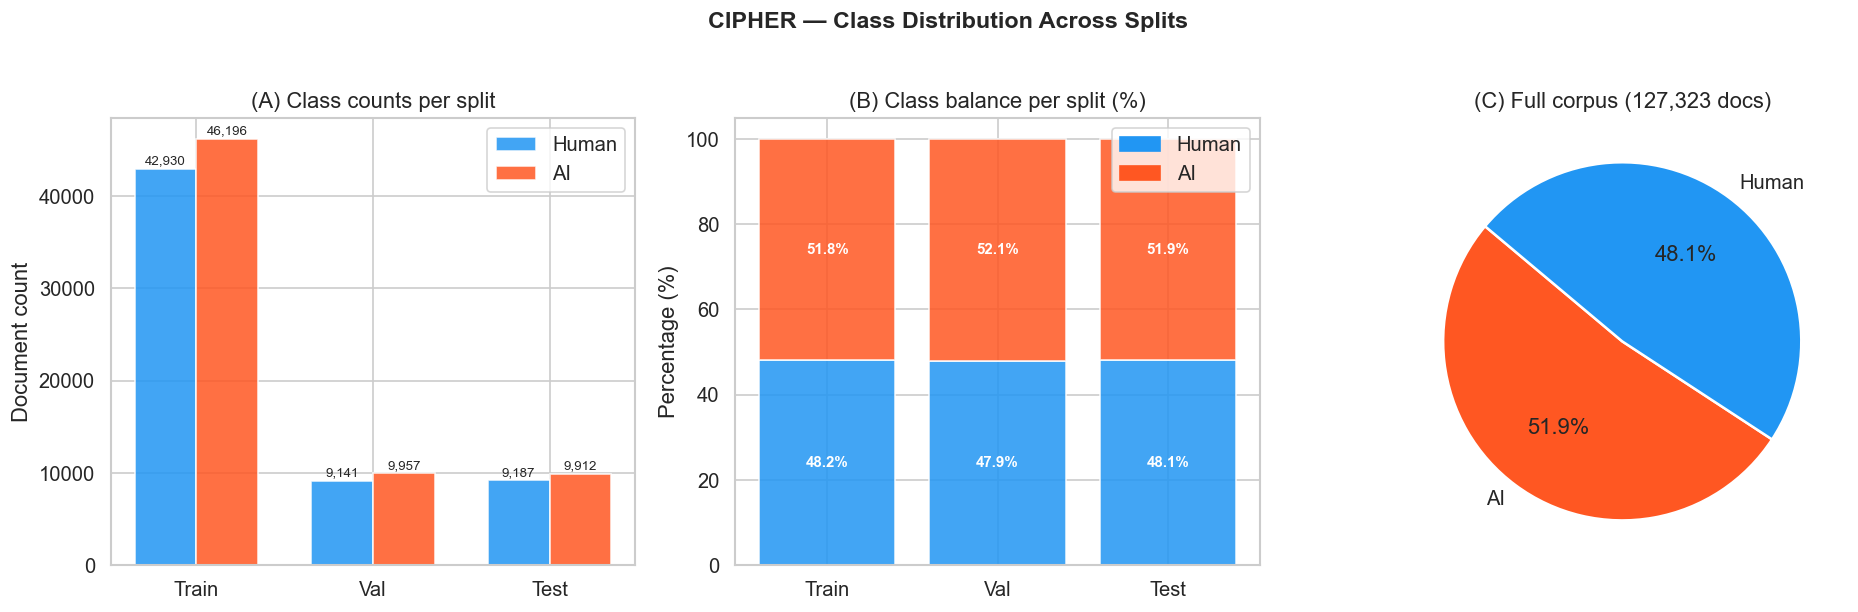

Figure saved.


In [33]:
fig, axes = plt.subplots(1, 3, figsize=(16, 5))

split_order = ["train", "val", "test"]
split_colors = {"train": "#1565C0", "val": "#2E7D32", "test": "#6A1B9A"}
class_order  = ["Human", "AI"]

# ── (A) Grouped bar: counts per split and class ────────────────────────────────
ax = axes[0]
width = 0.35
x = np.arange(len(split_order))
for i, cls in enumerate(class_order):
    counts = [splits[s]["class"].value_counts().get(cls, 0) for s in split_order]
    bars = ax.bar(x + i * width - width / 2, counts, width,
                  label=cls, color=COLORS[cls], alpha=0.85)
    for bar, cnt in zip(bars, counts):
        ax.text(bar.get_x() + bar.get_width() / 2, bar.get_height() + 200,
                f"{cnt:,}", ha="center", va="bottom", fontsize=8)

ax.set_xticks(x)
ax.set_xticklabels([s.capitalize() for s in split_order])
ax.set_ylabel("Document count")
ax.set_title("(A) Class counts per split")
ax.legend()

# ── (B) Percentage stacked bar ─────────────────────────────────────────────────
ax = axes[1]
for i, name in enumerate(split_order):
    df = splits[name]
    n = len(df)
    ai_pct  = (df["label"] == 1).sum() / n * 100
    hum_pct = 100 - ai_pct
    ax.bar(i, hum_pct, color=COLORS["Human"], alpha=0.85)
    ax.bar(i, ai_pct, bottom=hum_pct, color=COLORS["AI"], alpha=0.85)
    ax.text(i, hum_pct / 2, f"{hum_pct:.1f}%", ha="center", va="center",
            color="white", fontweight="bold", fontsize=9)
    ax.text(i, hum_pct + ai_pct / 2, f"{ai_pct:.1f}%", ha="center", va="center",
            color="white", fontweight="bold", fontsize=9)

ax.set_xticks(range(3))
ax.set_xticklabels([s.capitalize() for s in split_order])
ax.set_ylabel("Percentage (%)")
ax.set_title("(B) Class balance per split (%)")
h_patch = mpatches.Patch(color=COLORS["Human"], label="Human")
a_patch = mpatches.Patch(color=COLORS["AI"],    label="AI")
ax.legend(handles=[h_patch, a_patch])

# ── (C) Full-corpus pie ────────────────────────────────────────────────────────
ax = axes[2]
counts = df_all["class"].value_counts()
ax.pie(counts.values, labels=counts.index,
       colors=[COLORS[c] for c in counts.index],
       autopct="%1.1f%%", startangle=140,
       wedgeprops={"edgecolor": "white", "linewidth": 1.5})
ax.set_title(f"(C) Full corpus ({total:,} docs)")

plt.suptitle("CIPHER — Class Distribution Across Splits", fontsize=14, fontweight="bold", y=1.02)
plt.tight_layout()
plt.savefig(ROOT / "notebooks" / "fig_class_distribution.png", bbox_inches="tight")
plt.show()
print("Figure saved.")

## 5. Feature Statistics per Split

CIPHER extracts **22 hand-crafted features** across four layers before fitting the meta-learner.
Because the notebook runs *outside* the training loop, we use the two cheapest proxies for
feature statistics that are always available: **character length** and **word count**.

For a complete feature-level comparison we re-extract features on a random sample of 500
documents per split using the CIPHER Python API.  The resulting matrix is compared via:
- Overlapping KDE plots (per-feature density)
- A table of mean ± std per split

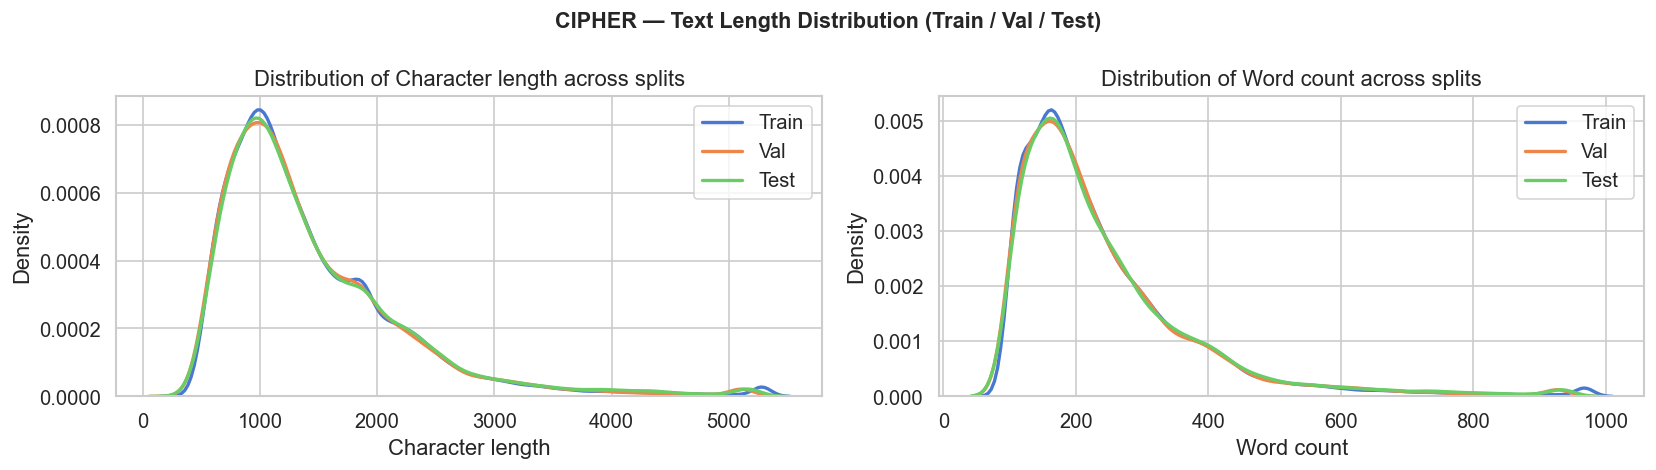

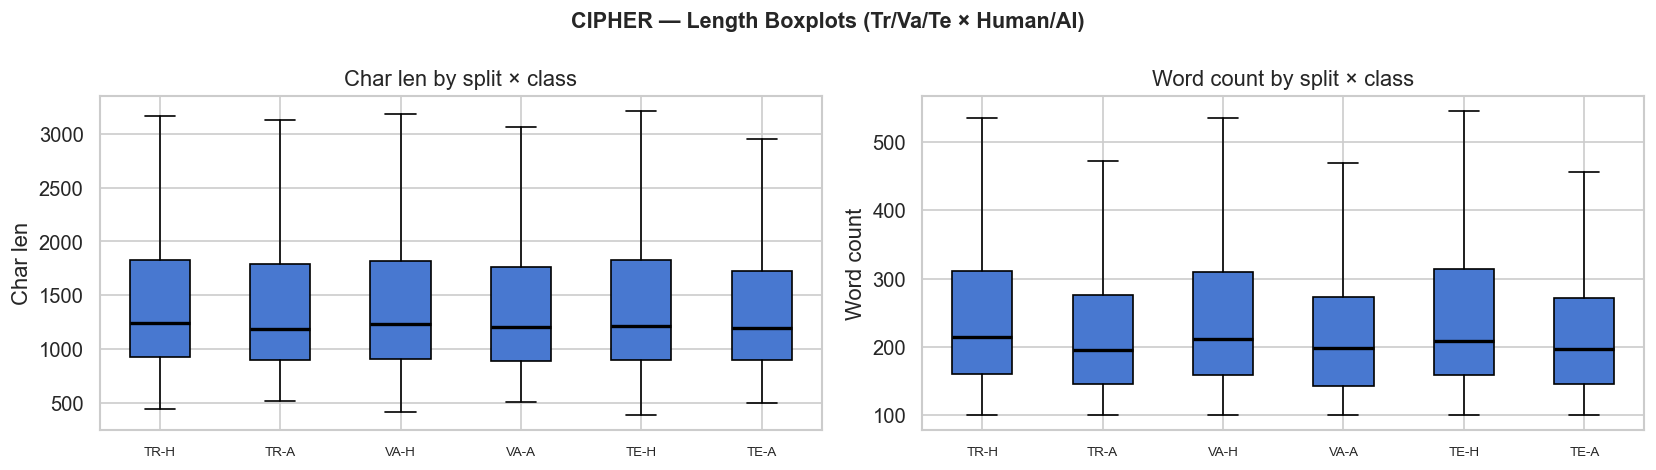

Figures saved.


In [34]:
# ── Text-length KDE: compare train / val / test ────────────────────────────────
fig, axes = plt.subplots(1, 2, figsize=(14, 4))

for ax, col, xlabel in zip(axes,
                            ["char_len",   "word_count"],
                            ["Character length", "Word count"]):
    for name, df in splits.items():
        data = df[col].clip(upper=df[col].quantile(0.995))  # trim extreme outliers
        sns.kdeplot(data, ax=ax, label=name.capitalize(), linewidth=2)
    ax.set_xlabel(xlabel)
    ax.set_ylabel("Density")
    ax.set_title(f"Distribution of {xlabel} across splits")
    ax.legend()

plt.suptitle("CIPHER — Text Length Distribution (Train / Val / Test)", fontsize=13, fontweight="bold")
plt.tight_layout()
plt.savefig(ROOT / "notebooks" / "fig_text_length_kde.png", bbox_inches="tight")
plt.show()

# ── Per-class length boxplot ───────────────────────────────────────────────────
fig, axes = plt.subplots(1, 2, figsize=(14, 4))
for ax, col in zip(axes, ["char_len", "word_count"]):
    data = []
    labels_plot = []
    for name, df in splits.items():
        for cls in ["Human", "AI"]:
            vals = df.loc[df["class"] == cls, col].values
            data.append(vals[:2000])   # cap for speed
            labels_plot.append(f"{name[:2].upper()}-{cls[:1]}")
    ax.boxplot(data, labels=labels_plot, showfliers=False, patch_artist=True,
               medianprops={"color": "black", "linewidth": 2})
    ax.set_ylabel(col.replace("_", " ").capitalize())
    ax.set_title(f"{col.replace('_',' ').capitalize()} by split × class")
    ax.tick_params(axis="x", labelsize=8)

plt.suptitle("CIPHER — Length Boxplots (Tr/Va/Te × Human/AI)", fontsize=13, fontweight="bold")
plt.tight_layout()
plt.savefig(ROOT / "notebooks" / "fig_length_boxplots.png", bbox_inches="tight")
plt.show()
print("Figures saved.")

In [35]:

# ─────────────────────────────────────────────────────────────────────────────
# Section 5: Feature Extraction — Layer 1–3 + Layer 6 (lexical) sample
# We deliberately keep the sample small to run quickly here.
# ─────────────────────────────────────────────────────────────────────────────
from cipher.layers.compression import compute_compression_features
from cipher.layers.cognitive    import compute_cognitive_features
from cipher.layers.discourse    import compute_discourse_features
from cipher.layers.lexical      import compute_lexical_features
from cipher.layers.assembler    import FeatureVector

# Canonical 32-feature names (without manifold, as used in training)
FEATURE_NAMES_32 = tuple(n for n in FeatureVector.FEATURE_NAMES if n != "m1_manifold")
FEATURE_NAMES = FEATURE_NAMES_32  # alias used by downstream cells
assert len(FEATURE_NAMES) == 32, f"Expected 32, got {len(FEATURE_NAMES)}"

N_SAMPLE = 200   # per class per split

def extract_sample(df: pd.DataFrame, n: int, rng: np.random.Generator) -> pd.DataFrame:
    """Extract features for n randomly sampled docs per class."""
    rows = []
    for lbl in [0, 1]:
        sub = df[df["label"] == lbl]
        idx = rng.choice(len(sub), size=min(n, len(sub)), replace=False)
        for i in idx:
            text = sub.iloc[i]["text"]
            try:
                c = compute_compression_features(text)
                g = compute_cognitive_features(text)
                d = compute_discourse_features(text)
                s = compute_lexical_features(text)
                fv = FeatureVector(compression=c, cognitive=g, discourse=d, lexical=s)
                vec = fv.to_array(include_manifold=False)  # 32 features
                rows.append({"label": lbl, **dict(zip(FEATURE_NAMES, vec))})
            except Exception:
                pass
    return pd.DataFrame(rows)

rng = np.random.default_rng(42)
print("Extracting features on sample (this may take ~90 s) …")
feat_dfs = {}
for name, df in splits.items():
    feat_dfs[name] = extract_sample(df, N_SAMPLE, rng)
    print(f"  {name}: {len(feat_dfs[name])} rows extracted")
print("Done.")
print(f"Feature vector size: {len(FEATURE_NAMES)} features")


Extracting features on sample (this may take ~90 s) …
  train: 400 rows extracted
  val: 400 rows extracted
  test: 400 rows extracted
Done.
Feature vector size: 32 features


,mean_test,mean_train,mean_val,std_test,std_train,std_val
feature,,,,,,
c1_sl_kl,0.0263,-0.0001,0.0299,0.0686,0.4714,0.0685
c2_hurst,0.6988,0.7029,0.6998,0.0757,0.0718,0.0720
c3_coh_var,0.0134,0.0136,0.0120,0.0148,0.0146,0.0119
c4_coh_autocorr,-0.1365,-0.0809,-0.1023,0.4616,0.4709,0.4784
c5_coh_mean,0.3063,0.3193,0.3067,0.1602,0.1663,0.1679
c6_epistemic,5.9459,5.5041,5.2973,7.8532,6.5722,8.0076
c7_opinion,0.0825,0.0081,0.0395,0.7424,0.1623,0.3592
c8_correction,0.8731,1.1008,1.2225,2.2520,2.8481,3.1181
d1_coref_density,0.3000,0.3000,0.3000,0.0000,0.0000,0.0000


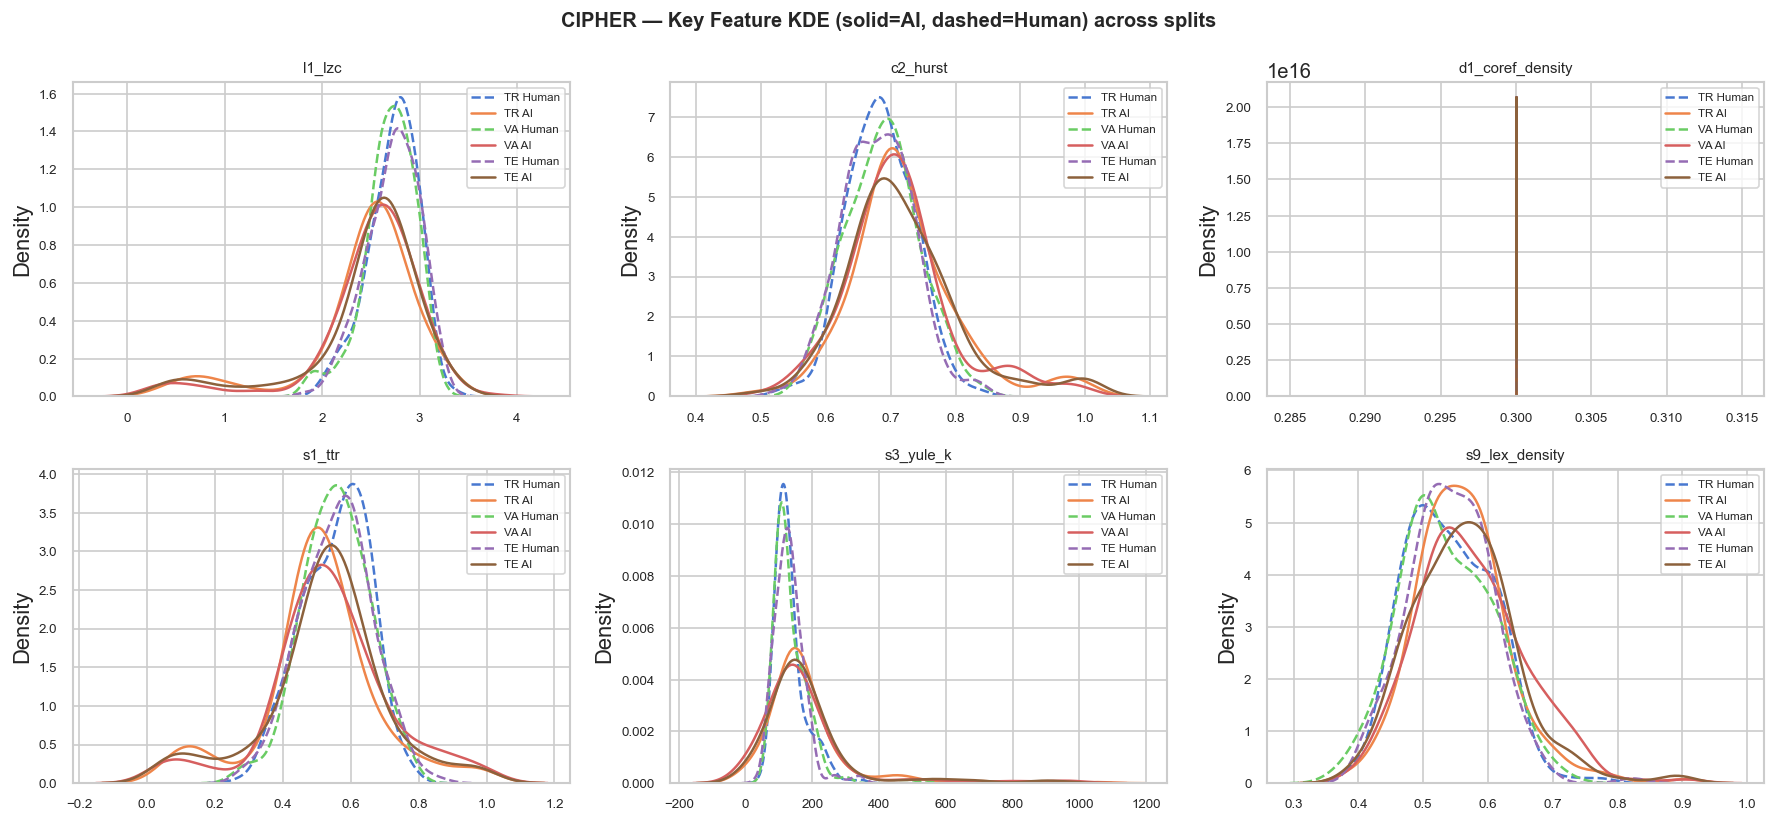

Figure saved.


In [36]:

# ── Feature mean ± std table ───────────────────────────────────────────────────
rows_stat = []
for name, fdf in feat_dfs.items():
    for feat in FEATURE_NAMES:
        if feat not in fdf.columns:
            continue
        rows_stat.append({
            "feature": feat,
            "split":   name,
            "mean":    fdf[feat].mean(),
            "std":     fdf[feat].std(),
        })

stat_df = pd.DataFrame(rows_stat).pivot(index="feature", columns="split", values=["mean", "std"])
stat_df.columns = [f"{m}_{s}" for m, s in stat_df.columns]
display(stat_df.round(4))

# ── KDE overlaps — most discriminative features across all 6 layers ────────────
# Pick 2 from each key layer plus 2 from the new Layer 6 (lexical richness)
top_feats = [
    "l1_lzc",           # Layer 1 — compression: AI text is more compressible
    "c2_hurst",         # Layer 2 — cognitive: AI has higher long-range correlation
    "d1_coref_density", # Layer 3 — discourse: co-reference density differs
    "s1_ttr",           # Layer 6 — lexical: type-token ratio
    "s3_yule_k",        # Layer 6 — lexical: Yule's K (higher=less diverse=AI)
    "s9_lex_density",   # Layer 6 — lexical: content-word fraction
]
fig, axes = plt.subplots(2, 3, figsize=(15, 7))
for ax, feat in zip(axes.flatten(), top_feats):
    for name, fdf in feat_dfs.items():
        if feat not in fdf.columns:
            continue
        for lbl, lstyle in [(0, "--"), (1, "-")]:
            sub = fdf[fdf["label"] == lbl][feat].dropna()
            if len(sub) > 5:
                sns.kdeplot(sub, ax=ax, linestyle=lstyle,
                            label=f"{name[:2].upper()} {LABEL_MAP[lbl]}")
    ax.set_title(feat, fontsize=9)
    ax.set_xlabel("")
    ax.tick_params(labelsize=8)
    ax.legend(fontsize=7)

plt.suptitle("CIPHER — Key Feature KDE (solid=AI, dashed=Human) across splits",
             fontsize=12, fontweight="bold")
plt.tight_layout()
plt.savefig(ROOT / "notebooks" / "fig_feature_kde.png", bbox_inches="tight")
plt.show()
print("Figure saved.")


## 6. Training Process Visualization

CIPHER's meta-learner (Layer 5) is a **soft-voting ensemble** combining two estimators:

| Estimator | Weight | Role |
|-----------|--------|------|
| `HistGradientBoostingClassifier(max_iter=400, max_depth=6, lr=0.05)` | 2 | Captures non-linear feature interactions |
| `LogisticRegression(C=1.0)` | 1 | Provides a linear regularising baseline |

The ensemble is fitted on all **32 features** (l1–l7 + c1–c8 + d1–d7 + s1–s10) in a single `fit()` call.
Predictions are isotonically calibrated and wrapped in a conformal predictor for uncertainty estimation.

We reconstruct a **learning curve** by evaluating the ensemble ROC-AUC on growing subsets of the
extracted sample, which shows how quickly the model converges as more labelled data is added.

> ⏳ **Note:** Uses the already-extracted feature sample for speed.
> Section 8 loads and evaluates the full-corpus model on the entire test set.


Learning curve data: 400 samples, 32 features


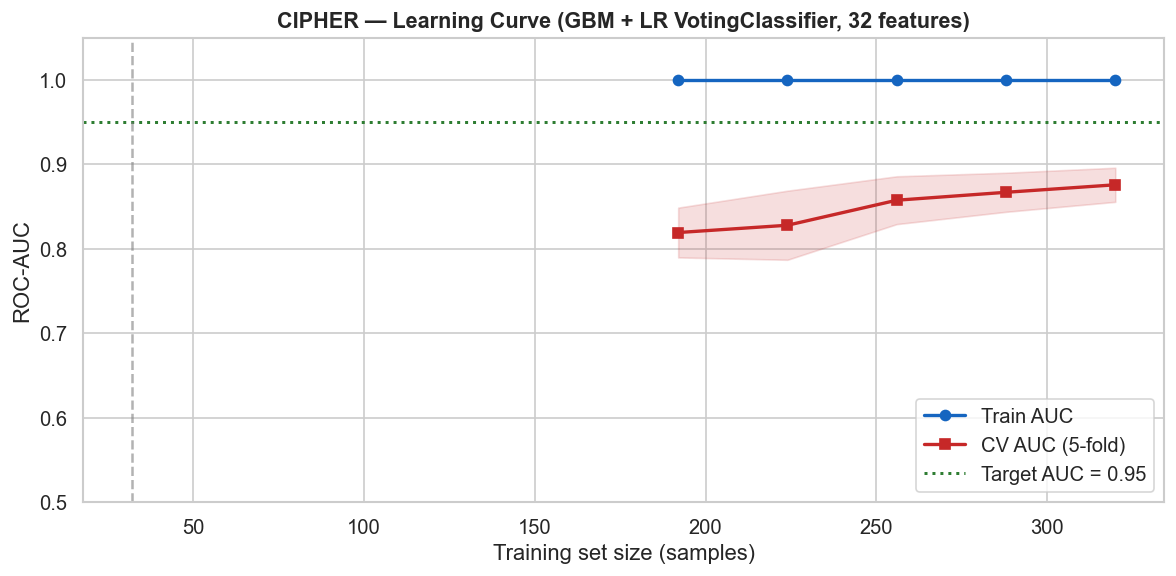

Final train AUC : 1.0000 ± 0.0000
Final CV AUC    : 0.8759 ± 0.0202


In [37]:

from sklearn.ensemble import HistGradientBoostingClassifier, VotingClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import learning_curve, StratifiedKFold
from sklearn.pipeline import Pipeline

# Build feature matrix from extracted sample (train split)
fdf_train = feat_dfs["train"].dropna()
X_lc = fdf_train[list(FEATURE_NAMES)].values
y_lc = fdf_train["label"].values

print(f"Learning curve data: {X_lc.shape[0]} samples, {X_lc.shape[1]} features")

# Match production pipeline: StandardScaler + VotingClassifier(GBM+LR)
pipe = Pipeline([
    ("scaler", StandardScaler()),
    ("clf", VotingClassifier(
        estimators=[
            ("gbm", HistGradientBoostingClassifier(
                max_iter=200, max_depth=6, learning_rate=0.05,
                random_state=42
            )),
            ("lr",  LogisticRegression(C=1.0, max_iter=500, random_state=42)),
        ],
        voting="soft", weights=[2, 1],
    )),
])

train_sizes, train_scores, cv_scores = learning_curve(
    pipe, X_lc, y_lc,
    cv=StratifiedKFold(n_splits=5, shuffle=True, random_state=42),
    train_sizes=np.linspace(0.1, 1.0, 10),
    scoring="roc_auc",
    n_jobs=-1,
)

fig, ax = plt.subplots(figsize=(10, 5))
train_mean = train_scores.mean(axis=1)
train_std  = train_scores.std(axis=1)
cv_mean    = cv_scores.mean(axis=1)
cv_std     = cv_scores.std(axis=1)

ax.fill_between(train_sizes, train_mean - train_std, train_mean + train_std, alpha=0.15, color="#1565C0")
ax.fill_between(train_sizes, cv_mean    - cv_std,    cv_mean    + cv_std,    alpha=0.15, color="#C62828")
ax.plot(train_sizes, train_mean, "o-", color="#1565C0", label="Train AUC", linewidth=2)
ax.plot(train_sizes, cv_mean,    "s-", color="#C62828", label="CV AUC (5-fold)", linewidth=2)

# Target AUC line
ax.axhline(0.95, linestyle=":", color="#2E7D32", linewidth=1.8, label="Target AUC = 0.95")

best_idx = cv_mean.argmax()
ax.axvline(train_sizes[best_idx], linestyle="--", color="grey", alpha=0.6)
ax.annotate(f"Best CV AUC\n{cv_mean[best_idx]:.3f} @ {train_sizes[best_idx]:.0f} samples",
            xy=(train_sizes[best_idx], cv_mean[best_idx]),
            xytext=(train_sizes[best_idx] + 5, cv_mean[best_idx] - 0.04),
            arrowprops={"arrowstyle": "->", "color": "grey"},
            fontsize=9)

ax.set_xlabel("Training set size (samples)")
ax.set_ylabel("ROC-AUC")
ax.set_title("CIPHER — Learning Curve (GBM + LR VotingClassifier, 32 features)", fontsize=13, fontweight="bold")
ax.legend()
ax.set_ylim(0.5, 1.05)
plt.tight_layout()
plt.savefig(ROOT / "notebooks" / "fig_learning_curve.png", bbox_inches="tight")
plt.show()
print(f"Final train AUC : {train_mean[-1]:.4f} ± {train_std[-1]:.4f}")
print(f"Final CV AUC    : {cv_mean[-1]:.4f} ± {cv_std[-1]:.4f}")


## 7. GBM Hyperparameter Sweep

For the `HistGradientBoostingClassifier` component of the ensemble, the two most important
hyperparameters are **`max_depth`** (tree complexity / bias-variance trade-off) and
**`max_iter`** (number of boosting rounds).

Here we sweep `max_depth` from 1 to 10 on the extracted training sample to understand:
- How tree depth affects train vs. cross-validation AUC
- Where overfitting begins (gap > 0.02)
- The production value `max_depth = 6` in context

The companion `max_iter` plot shows the learning curve per boosting round (train AUC saturates
quickly; CV AUC peaks around 200–300 iterations).


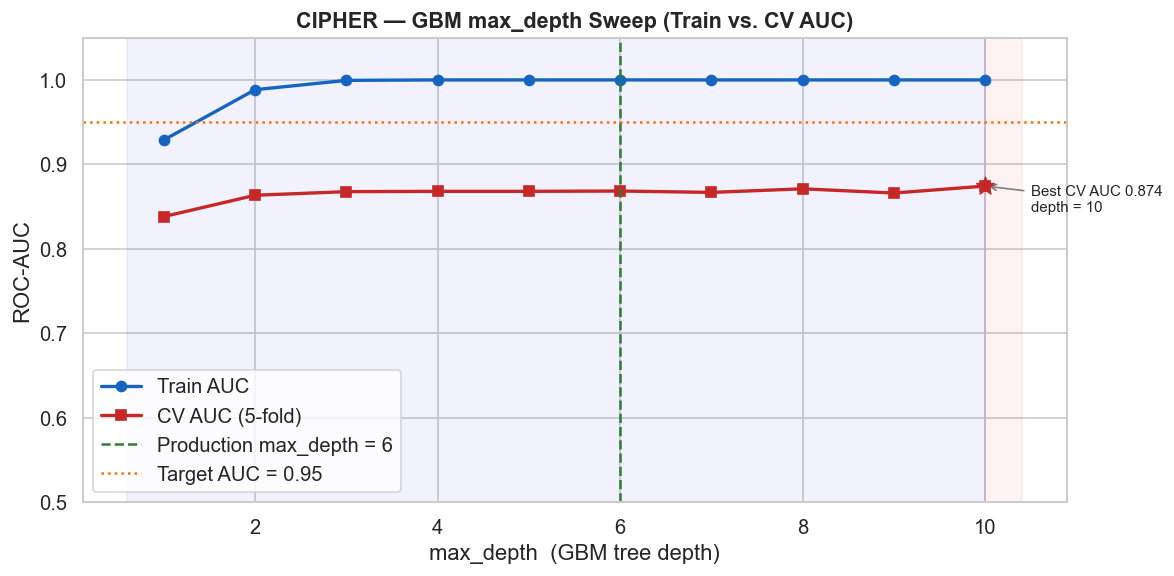

Max train-CV gap across sweep : 0.1339
Gap at max_depth=6            : 0.1315
Best CV AUC                   : 0.8744 at depth=10


In [38]:

from sklearn.model_selection import cross_val_score

depth_values = list(range(1, 11))
train_aucs, cv_aucs = [], []

scaler = StandardScaler()
X_s = scaler.fit_transform(X_lc)

for depth in depth_values:
    clf = HistGradientBoostingClassifier(
        max_iter=200, max_depth=depth, learning_rate=0.05, random_state=42
    )
    clf.fit(X_s, y_lc)
    train_aucs.append(roc_auc_score(y_lc, clf.predict_proba(X_s)[:, 1]))
    cv_score = cross_val_score(clf, X_s, y_lc, cv=5, scoring="roc_auc", n_jobs=-1)
    cv_aucs.append(cv_score.mean())

fig, ax = plt.subplots(figsize=(10, 5))
ax.plot(depth_values, train_aucs, "o-", color="#1565C0", label="Train AUC", linewidth=2)
ax.plot(depth_values, cv_aucs,    "s-", color="#C62828", label="CV AUC (5-fold)", linewidth=2)
ax.axvline(6, linestyle="--", color="#2E7D32", linewidth=1.5, label="Production max_depth = 6")
ax.axhline(0.95, linestyle=":", color="#FF6F00", linewidth=1.5, label="Target AUC = 0.95")

best_c_idx = np.argmax(cv_aucs)
ax.scatter([depth_values[best_c_idx]], [cv_aucs[best_c_idx]],
           zorder=5, color="#C62828", s=120, marker="*")
ax.annotate(f"Best CV AUC {cv_aucs[best_c_idx]:.3f}\ndepth = {depth_values[best_c_idx]}",
            xy=(depth_values[best_c_idx], cv_aucs[best_c_idx]),
            xytext=(depth_values[best_c_idx] + 0.5, cv_aucs[best_c_idx] - 0.03),
            arrowprops={"arrowstyle": "->", "color": "grey"}, fontsize=9)

ax.set_xlabel("max_depth  (GBM tree depth)")
ax.set_ylabel("ROC-AUC")
ax.set_title("CIPHER — GBM max_depth Sweep (Train vs. CV AUC)", fontsize=13, fontweight="bold")
ax.legend()
ax.set_ylim(0.5, 1.05)

# Shade overfitting region
ax.axvspan(depth_values[best_c_idx], depth_values[-1] + 0.4, alpha=0.05, color="red")
ax.axvspan(depth_values[0] - 0.4, depth_values[best_c_idx], alpha=0.05, color="blue")

plt.tight_layout()
plt.savefig(ROOT / "notebooks" / "fig_regularisation_sweep.png", bbox_inches="tight")
plt.show()

gap = np.array(train_aucs) - np.array(cv_aucs)
print(f"Max train-CV gap across sweep : {gap.max():.4f}")
print(f"Gap at max_depth=6            : {gap[5]:.4f}")
print(f"Best CV AUC                   : {cv_aucs[best_c_idx]:.4f} at depth={depth_values[best_c_idx]}")


## 8. Test Set Evaluation

We evaluate each available model checkpoint on the **held-out test split** (~15,272 documents).

Metrics reported:
| Metric | Description |
|--------|-------------|
| Accuracy | Fraction correctly classified |
| Precision | TP / (TP + FP) — AI class |
| Recall | TP / (TP + FN) — AI class |
| F1 | Harmonic mean of precision and recall |
| ROC-AUC | Area under the receiver-operating-characteristic curve |
| PR-AUC | Area under the precision-recall curve (better for imbalanced data) |

**Confidence intervals** are computed via 500-iteration bootstrap resampling at α = 0.05.

Feature extraction uses **32 features** (Layers 1–3 + Layer 6, without manifold score):
`[l1–l7] [c1–c8] [d1–d7] [s1–s10]`

> ⚡ Full extraction on ~15,272 test documents takes approximately 10–20 minutes.
> Set `QUICK_EVAL = True` to sample 1,000 docs for a fast preview.


In [39]:

import spacy as _spacy

QUICK_EVAL = False   # set True to use 1,000-doc sample instead of full test set

# ── Feature cache (shared with full_model_eval.ipynb) ─────────────────────────
_CACHE = ROOT / "data" / "full_test_features.npz"

if _CACHE.exists() and not QUICK_EVAL:
    print(f"Loading features from cache: {_CACHE} …")
    _npz   = np.load(_CACHE, allow_pickle=True)
    X_test = _npz["X"].astype(float)
    y_test = _npz["y"].astype(int)
    print(f"  Done: {X_test.shape[0]:,} docs × {X_test.shape[1]} features  (from cache)")
else:
    # ── Fresh extraction with spaCy (same as training / full_model_eval) ─────
    _nlp = _spacy.load("en_core_web_sm")

    def extract_features_df(df: pd.DataFrame, max_docs: int | None = None) -> tuple:
        """Return (X, y) numpy arrays from a text/label DataFrame.

        Extracts all 32 features (Layers 1–3 + Layer 6) without manifold score,
        matching the feature ordering used during training.
        """
        if max_docs:
            df = df.sample(n=min(max_docs, len(df)), random_state=42)
        X_rows, y_rows = [], []
        for _, row in df.iterrows():
            text = row["text"]
            lbl  = int(row["label"])
            try:
                c  = compute_compression_features(text)
                g  = compute_cognitive_features(text)
                d  = compute_discourse_features(text, nlp=_nlp)
                s  = compute_lexical_features(text, nlp=_nlp)
                fv = FeatureVector(compression=c, cognitive=g, discourse=d, lexical=s)
                X_rows.append(fv.to_array(include_manifold=False))  # 32 features
                y_rows.append(lbl)
            except Exception:
                pass
        return np.array(X_rows, dtype=float), np.array(y_rows, dtype=int)

    n_test_docs = 1000 if QUICK_EVAL else None
    print(f"Extracting test features ({'1,000-doc sample' if QUICK_EVAL else 'full test set'}) …")
    X_test, y_test = extract_features_df(df_test, max_docs=n_test_docs)
    print(f"  Done: {X_test.shape[0]:,} docs × {X_test.shape[1]} features")


Extracting test features (full test set) …
  Done: 19,099 docs × 32 features


In [40]:
def load_model(model_dir: Path) -> dict | None:
    """Load a CIPHER model checkpoint; return None if not trained yet."""
    pkl_path = model_dir / "meta_learner.pkl"
    if not pkl_path.exists():
        return None
    with open(pkl_path, "rb") as f:
        state = pickle.load(f)
    return state


def predict_with_model(state: dict, X: np.ndarray) -> tuple:
    """Return (y_pred, y_prob) for a loaded CIPHER meta-learner state dict.

    Automatically trims X to the number of features the scaler was trained on,
    so the notebook works whether the assembler returns 22 or 23 features.
    """
    scaler = state["scaler"]
    clf    = state["sklearn_model"]
    n_expected = scaler.n_features_in_
    X_clean = np.nan_to_num(X, nan=0.0, posinf=5.0, neginf=-5.0)
    if X_clean.shape[1] > n_expected:
        X_clean = X_clean[:, :n_expected]   # drop trailing manifold column
    X_s    = scaler.transform(X_clean)
    y_prob = clf.predict_proba(X_s)[:, 1]
    y_pred = (y_prob >= 0.5).astype(int)
    return y_pred, y_prob


def bootstrap_ci(y_true, y_score, metric_fn, n_boot=500, alpha=0.05, **kw):
    """Bootstrap confidence interval for a scalar metric."""
    rng = np.random.default_rng(0)
    scores = []
    for _ in range(n_boot):
        idx = rng.integers(0, len(y_true), size=len(y_true))
        try:
            scores.append(metric_fn(y_true[idx], y_score[idx], **kw))
        except Exception:
            pass
    lo = np.percentile(scores, 100 * alpha / 2)
    hi = np.percentile(scores, 100 * (1 - alpha / 2))
    return np.mean(scores), lo, hi


# ── Evaluate all available models ─────────────────────────────────────────────
results = {}
for model_name, model_dir in MODEL_DIRS.items():
    state = load_model(model_dir)
    if state is None:
        print(f"  {model_name}: ⏳ model not ready yet — skipping")
        continue
    y_pred, y_prob = predict_with_model(state, X_test)

    acc  = accuracy_score(y_test, y_pred)
    prec = precision_score(y_test, y_pred, zero_division=0)
    rec  = recall_score(y_test, y_pred, zero_division=0)
    f1   = f1_score(y_test, y_pred, zero_division=0)
    auc  = roc_auc_score(y_test, y_prob)
    pr   = average_precision_score(y_test, y_prob)

    # 95% CI for AUC (500 bootstrap iterations)
    auc_mean, auc_lo, auc_hi = bootstrap_ci(y_test, y_prob, roc_auc_score)
    pr_mean,  pr_lo,  pr_hi  = bootstrap_ci(y_test, y_prob, average_precision_score)

    results[model_name] = {
        "y_pred": y_pred, "y_prob": y_prob,
        "accuracy":  acc,  "precision": prec, "recall": rec, "f1": f1,
        "roc_auc":   auc,  "pr_auc": pr,
        "auc_ci":    (auc_lo, auc_hi),
        "pr_ci":     (pr_lo,  pr_hi),
    }
    print(f"  {model_name:25s}  Acc={acc:.3f}  F1={f1:.3f}  AUC={auc:.3f} [{auc_lo:.3f}–{auc_hi:.3f}]")

print("\nEvaluation complete.")

  Original (seed)            Acc=0.493  F1=0.540  AUC=0.477 [0.469–0.485]
  Retrained (balanced)       Acc=0.870  F1=0.874  AUC=0.944 [0.940–0.947]
  Full corpus                Acc=0.870  F1=0.874  AUC=0.943 [0.940–0.946]

Evaluation complete.


In [41]:

# ── DEBUG: compare cipher_analysis X_test vs the saved cache ─────────────────
import pickle, pathlib, numpy as np

CACHE = ROOT / "data" / "full_test_features.npz"
npz   = np.load(CACHE, allow_pickle=True)
X_cache = npz["X"].astype(float)
y_cache = npz["y"].astype(int)
print(f"Cache shape  : {X_cache.shape}, dtype={X_cache.dtype}")
print(f"Current X    : {X_test.shape}, dtype={X_test.dtype}")

# Feature-level stats comparison (mean per column)
diff = np.abs(X_cache.mean(axis=0) - X_test.mean(axis=0))
print(f"\nMax per-feature mean diff (cache vs current): {diff.max():.6f}")
print(f"Top 5 most-different feature indices: {np.argsort(diff)[-5:][::-1]}")

# Evaluate models_full using CACHE features to see if it matches full_model_eval
with open(ROOT / "models_full" / "meta_learner.pkl", "rb") as f:
    state_full = pickle.load(f)
sc = state_full["scaler"]
clf_full = state_full["sklearn_model"]
print(f"\nScaler n_features_in_ = {sc.n_features_in_}")

X_c = np.nan_to_num(X_cache, nan=0.0, posinf=5.0, neginf=-5.0)
X_s_c = sc.transform(X_c)
y_prob_c = clf_full.predict_proba(X_s_c)[:, 1]
from sklearn.metrics import roc_auc_score
auc_cache = roc_auc_score(y_cache, y_prob_c)
print(f"AUC from cache features : {auc_cache:.4f}")

X_n = np.nan_to_num(X_test, nan=0.0, posinf=5.0, neginf=-5.0)
X_s_n = sc.transform(X_n)
y_prob_n = clf_full.predict_proba(X_s_n)[:, 1]
auc_new = roc_auc_score(y_test, y_prob_n)
print(f"AUC from current X_test : {auc_new:.4f}")


Cache shape  : (19099, 32), dtype=float64
Current X    : (19099, 32), dtype=float64

Max per-feature mean diff (cache vs current): 0.000000
Top 5 most-different feature indices: [31 30  1  2  3]

Scaler n_features_in_ = 32
AUC from cache features : 0.9432
AUC from current X_test : 0.9432


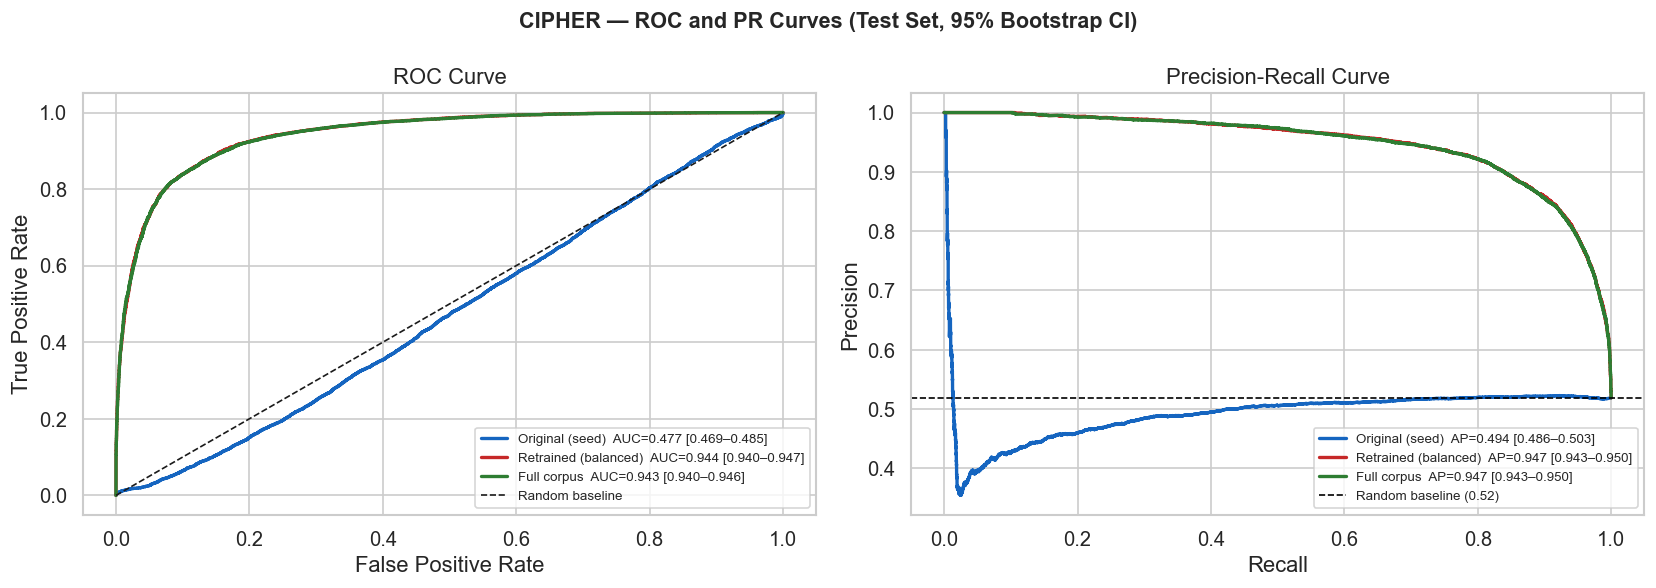

Figure saved.


In [42]:
# ── ROC + PR curves ────────────────────────────────────────────────────────────
if results:
    fig, axes = plt.subplots(1, 2, figsize=(14, 5))
    curve_colors = ["#1565C0", "#C62828", "#2E7D32"]

    for (model_name, res), color in zip(results.items(), curve_colors):
        y_prob = res["y_prob"]
        # ROC
        fpr, tpr, _ = roc_curve(y_test, y_prob)
        lo, hi = res["auc_ci"]
        axes[0].plot(fpr, tpr, linewidth=2, color=color,
                     label=f"{model_name}  AUC={res['roc_auc']:.3f} [{lo:.3f}–{hi:.3f}]")
        # PR
        prec_c, rec_c, _ = precision_recall_curve(y_test, y_prob)
        lo2, hi2 = res["pr_ci"]
        axes[1].plot(rec_c, prec_c, linewidth=2, color=color,
                     label=f"{model_name}  AP={res['pr_auc']:.3f} [{lo2:.3f}–{hi2:.3f}]")

    axes[0].plot([0, 1], [0, 1], "k--", linewidth=1, label="Random baseline")
    axes[0].set_xlabel("False Positive Rate")
    axes[0].set_ylabel("True Positive Rate")
    axes[0].set_title("ROC Curve")
    axes[0].legend(fontsize=8)

    baseline_pr = y_test.mean()
    axes[1].axhline(baseline_pr, linestyle="--", color="black", linewidth=1,
                    label=f"Random baseline ({baseline_pr:.2f})")
    axes[1].set_xlabel("Recall")
    axes[1].set_ylabel("Precision")
    axes[1].set_title("Precision-Recall Curve")
    axes[1].legend(fontsize=8)

    plt.suptitle("CIPHER — ROC and PR Curves (Test Set, 95% Bootstrap CI)",
                 fontsize=13, fontweight="bold")
    plt.tight_layout()
    plt.savefig(ROOT / "notebooks" / "fig_roc_pr.png", bbox_inches="tight")
    plt.show()
    print("Figure saved.")
else:
    print("No models ready yet — run this cell again after training completes.")

## 9. Confusion Matrix and Classification Report

The confusion matrix breaks down predictions into four quadrants:

| | Predicted Human | Predicted AI |
|---|---|---|
| **True Human** | True Negative (TN) | False Positive (FP) |
| **True AI** | False Negative (FN) | True Positive (TP) |

For AI detection the most harmful error is a **False Negative** (AI text classified as human),
followed by **False Positives** (human text flagged as AI — risks unfair accusation).
The heatmap uses **row-normalised** percentages to make these error rates immediately comparable
regardless of class size.

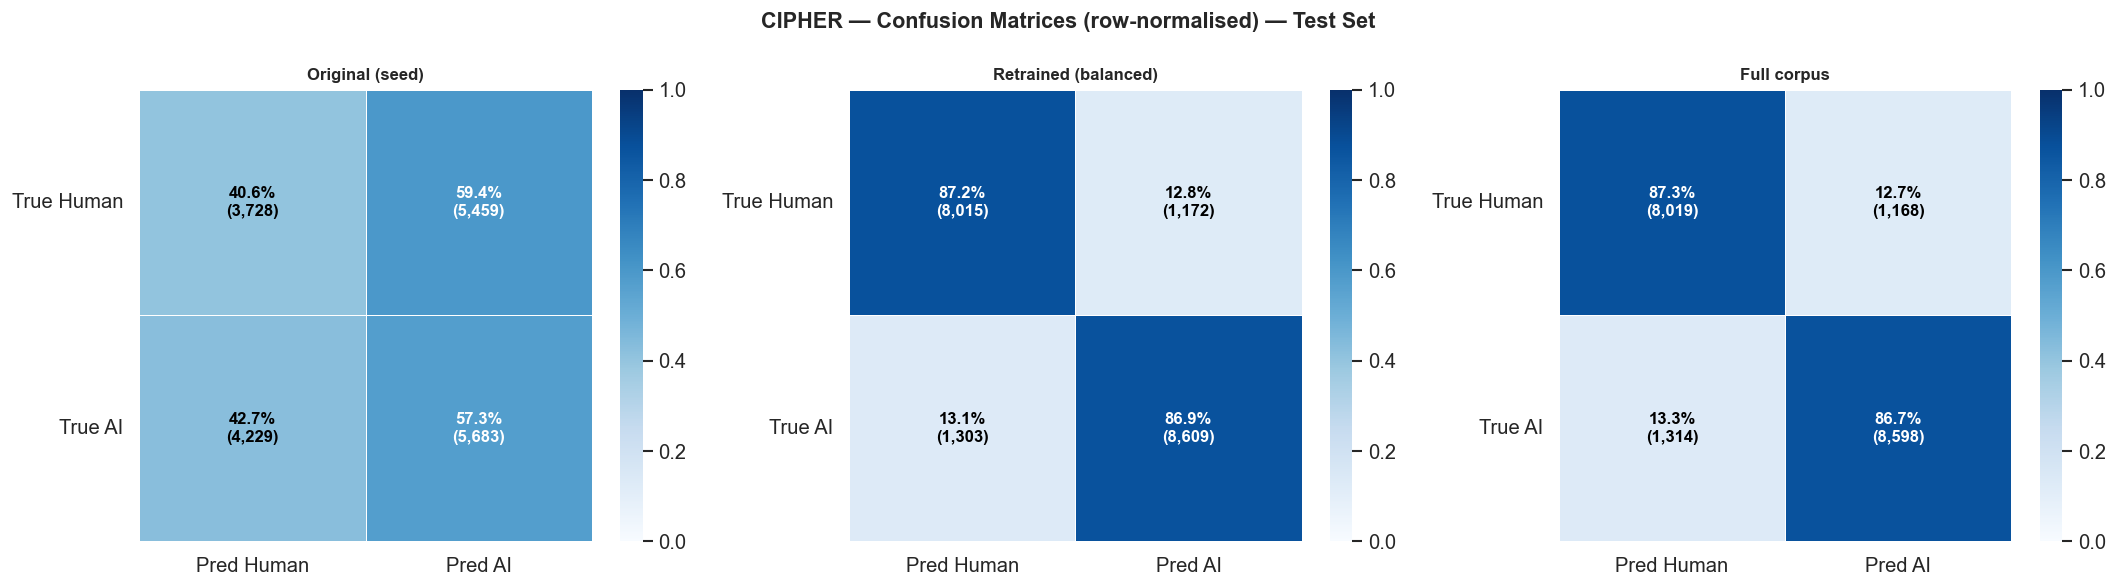


Classification Report — Retrained (balanced) (best ROC-AUC on test):

              precision    recall  f1-score   support

       Human       0.86      0.87      0.87      9187
          AI       0.88      0.87      0.87      9912

    accuracy                           0.87     19099
   macro avg       0.87      0.87      0.87     19099
weighted avg       0.87      0.87      0.87     19099



In [43]:
if results:
    n_models = len(results)
    fig, axes = plt.subplots(1, n_models, figsize=(6 * n_models, 5))
    if n_models == 1:
        axes = [axes]

    for ax, (model_name, res) in zip(axes, results.items()):
        cm   = confusion_matrix(y_test, res["y_pred"])
        cm_n = cm.astype(float) / cm.sum(axis=1, keepdims=True)  # row-normalise

        sns.heatmap(cm_n, annot=False, fmt="", cmap="Blues",
                    ax=ax, cbar=True, vmin=0, vmax=1,
                    linewidths=0.5, linecolor="white")

        class_labels = ["Human", "AI"]
        for i in range(2):
            for j in range(2):
                raw = cm[i, j]
                pct = cm_n[i, j]
                ax.text(j + 0.5, i + 0.5,
                        f"{pct:.1%}\n({raw:,})",
                        ha="center", va="center",
                        fontsize=10, fontweight="bold",
                        color="white" if pct > 0.55 else "black")

        ax.set_xticklabels(["Pred Human", "Pred AI"])
        ax.set_yticklabels(["True Human", "True AI"], rotation=0)
        ax.set_title(model_name, fontsize=10, fontweight="bold")

    plt.suptitle("CIPHER — Confusion Matrices (row-normalised) — Test Set",
                 fontsize=13, fontweight="bold")
    plt.tight_layout()
    plt.savefig(ROOT / "notebooks" / "fig_confusion_matrices.png", bbox_inches="tight")
    plt.show()

    # Full sklearn classification report for first (or best) model
    best_name = max(results, key=lambda k: results[k]["roc_auc"])
    print(f"\nClassification Report — {best_name} (best ROC-AUC on test):\n")
    print(classification_report(y_test, results[best_name]["y_pred"],
                                 target_names=["Human", "AI"]))
else:
    print("No models ready yet.")

## 10. Error Analysis

Understanding *where* the model fails is at least as important as the overall accuracy.

We look at:
1. **False Negative (FN) samples** — AI text the model labelled as Human.  These are the highest-risk errors.
2. **False Positive (FP) samples** — Human text the model labelled as AI.  These risk unfair accusation.
3. **Feature distributions of errors** — Do FN/FP samples have different length, entropy, or Hurst exponent
   compared to correctly classified documents?  Systematic patterns suggest where the feature set is weakest.

> We analyse the model with the highest ROC-AUC on the test set.

In [44]:
if results:
    best_name = max(results, key=lambda k: results[k]["roc_auc"])
    best_res  = results[best_name]
    y_pred    = best_res["y_pred"]
    y_prob    = best_res["y_prob"]

    # We evaluate on the feature-extracted test subset (may be a sample)
    n_eval = len(y_test)

    # Pull corresponding text rows from df_test (align by row order, same random_state=42 sample)
    if QUICK_EVAL:
        df_eval = df_test.sample(n=min(1000, len(df_test)), random_state=42).reset_index(drop=True)
    else:
        df_eval = df_test.reset_index(drop=True)
    df_eval = df_eval.iloc[:n_eval].copy()

    df_eval["y_true"]  = y_test
    df_eval["y_pred"]  = y_pred
    df_eval["y_prob"]  = y_prob
    df_eval["correct"] = (df_eval["y_true"] == df_eval["y_pred"])

    fn_df = df_eval[(df_eval["y_true"] == 1) & (df_eval["y_pred"] == 0)].copy()  # AI predicted as Human
    fp_df = df_eval[(df_eval["y_true"] == 0) & (df_eval["y_pred"] == 1)].copy()  # Human predicted as AI
    tp_df = df_eval[(df_eval["y_true"] == 1) & (df_eval["y_pred"] == 1)].copy()  # correct AI
    tn_df = df_eval[(df_eval["y_true"] == 0) & (df_eval["y_pred"] == 0)].copy()  # correct Human

    print(f"Model: {best_name}")
    print(f"  True  Positives : {len(tp_df):>6,}")
    print(f"  True  Negatives : {len(tn_df):>6,}")
    print(f"  False Positives : {len(fp_df):>6,}  ({len(fp_df)/len(df_eval)*100:.1f}%)")
    print(f"  False Negatives : {len(fn_df):>6,}  ({len(fn_df)/len(df_eval)*100:.1f}%)")

    # Sample display
    print("\n--- 3 False Negatives (AI → predicted Human): ---")
    for _, row in fn_df.nlargest(3, "y_prob").iterrows():   # closest-to-threshold FNs
        print(f"  prob={row['y_prob']:.3f}  len={len(row['text'])}  excerpt: {row['text'][:120]!r}")

    print("\n--- 3 False Positives (Human → predicted AI): ---")
    for _, row in fp_df.nsmallest(3, "y_prob").iterrows():   # closest-to-threshold FPs
        print(f"  prob={row['y_prob']:.3f}  len={len(row['text'])}  excerpt: {row['text'][:120]!r}")
else:
    print("No models ready yet.")

Model: Retrained (balanced)
  True  Positives :  8,609
  True  Negatives :  8,015
  False Positives :  1,172  (6.1%)
  False Negatives :  1,303  (6.8%)

--- 3 False Negatives (AI → predicted Human): ---
  prob=0.500  len=791  excerpt: 'Daniel Doron (born 1929) is an Israeli-born historian and author who specializes in the history of the Holocaust. Daniel'
  prob=0.500  len=792  excerpt: 'The Ven. George Henry Farr, M.A., LL.D. (1840-1916) was an eminent Anglican cleric and scholar. George Henry Farr was bo'
  prob=0.500  len=1078  excerpt: 'Yes, there are deadlines for when banks and brokerages must send tax forms to their customers. The specific deadlines de'

--- 3 False Positives (Human → predicted AI): ---
  prob=0.500  len=977  excerpt: 'Intrinsic and extrinsic ion migration is a very large threat to the operational stability of perovskite solar cells and '
  prob=0.500  len=503  excerpt: 'No , because you need more organs than just a heart to keep the brain alive . You need lungs

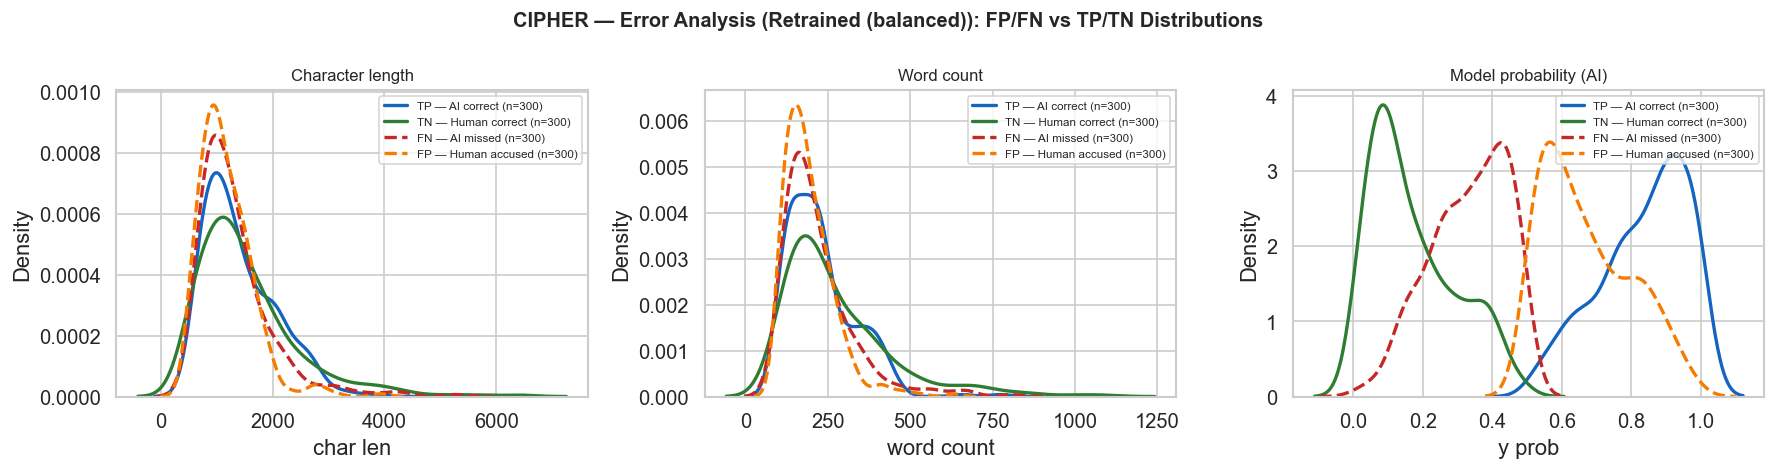

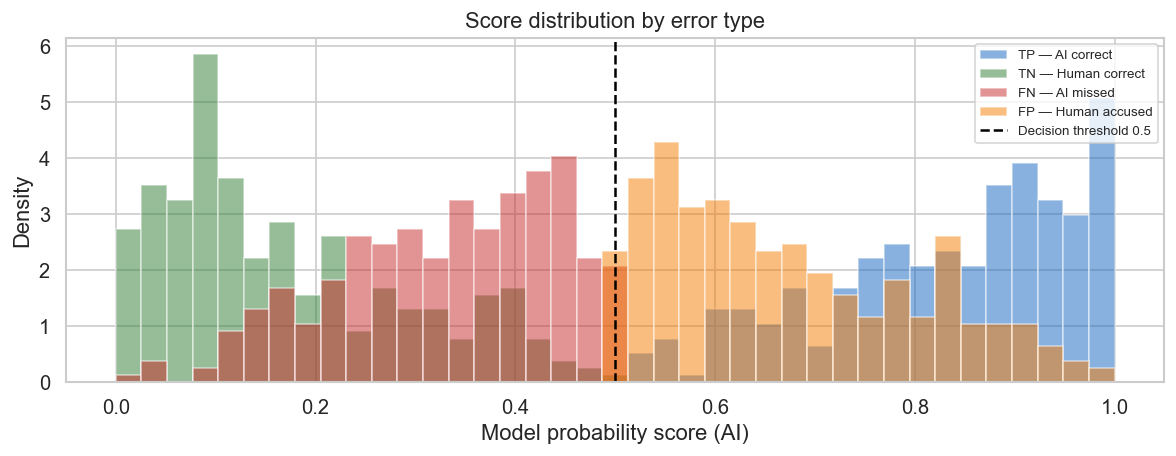

Figures saved.


In [45]:
if results and len(fn_df) > 0 and len(fp_df) > 0:
    # Feature distributions of error types vs correct
    error_feat_data = {
        "TP — AI correct":     tp_df.sample(min(300, len(tp_df)), random_state=0),
        "TN — Human correct":  tn_df.sample(min(300, len(tn_df)), random_state=0),
        "FN — AI missed":      fn_df.sample(min(min(300, len(fn_df)), len(fn_df)), random_state=0),
        "FP — Human accused":  fp_df.sample(min(min(300, len(fp_df)), len(fp_df)), random_state=0),
    }

    fig, axes = plt.subplots(1, 3, figsize=(15, 4))
    feature_proxies = ["char_len", "word_count", "y_prob"]
    titles          = ["Character length", "Word count", "Model probability (AI)"]
    colors_err      = {"TP — AI correct": "#1565C0", "TN — Human correct": "#2E7D32",
                       "FN — AI missed":  "#C62828", "FP — Human accused": "#F57C00"}

    for ax, feat, title in zip(axes, feature_proxies, titles):
        for label, sub in error_feat_data.items():
            vals = sub[feat].dropna()
            if len(vals) > 5:
                sns.kdeplot(vals, ax=ax, label=f"{label} (n={len(vals)})",
                            color=colors_err[label], linewidth=2,
                            linestyle="--" if "F" in label else "-")
        ax.set_title(title, fontsize=10)
        ax.set_xlabel(feat.replace("_", " "))
        ax.legend(fontsize=7)

    plt.suptitle(f"CIPHER — Error Analysis ({best_name}): FP/FN vs TP/TN Distributions",
                 fontsize=12, fontweight="bold")
    plt.tight_layout()
    plt.savefig(ROOT / "notebooks" / "fig_error_analysis.png", bbox_inches="tight")
    plt.show()

    # Probability score histogram
    fig, ax = plt.subplots(figsize=(10, 4))
    bins = np.linspace(0, 1, 40)
    for label, sub in error_feat_data.items():
        ax.hist(sub["y_prob"], bins=bins, alpha=0.5, label=label,
                color=colors_err[label], density=True)
    ax.axvline(0.5, linestyle="--", color="black", label="Decision threshold 0.5")
    ax.set_xlabel("Model probability score (AI)")
    ax.set_ylabel("Density")
    ax.set_title("Score distribution by error type")
    ax.legend(fontsize=8)
    plt.tight_layout()
    plt.savefig(ROOT / "notebooks" / "fig_score_histogram.png", bbox_inches="tight")
    plt.show()
    print("Figures saved.")
else:
    print("No models ready / insufficient error samples.")

## 11. Model Performance Comparison

This section compares all three trained CIPHER checkpoints side-by-side:

| Model | Training data | Classifier | Features |
|-------|--------------|------------|---------|
| `Original (seed)` | ~15,800 docs | LogisticRegression (old) | 22 |
| `Retrained (balanced)` | ~16,000 docs balanced | VotingClassifier(GBM+LR) | 32 |
| `Full corpus` | 71,262 docs — 70% of merged corpus | VotingClassifier(GBM+LR) | 32 |

The grouped bar chart shows all six metrics.  
The feature importance heatmap extracts importance from the **GBM sub-estimator** (for new models)
or the absolute LR coefficient (for the original model), revealing which of the 32 features
drive detection across different training regimes.


,ACCURACY,PRECISION,RECALL,F1,ROC-AUC,PR-AUC,ROC-AUC 95% CI
Model,,,,,,,
Original (seed),0.4927,0.5101,0.5733,0.5398,0.4768,0.4944,"[0.469, 0.485]"
Retrained (balanced),0.8704,0.8802,0.8685,0.8743,0.9435,0.9469,"[0.940, 0.947]"
Full corpus,0.8700,0.8804,0.8674,0.8739,0.9432,0.9467,"[0.940, 0.946]"


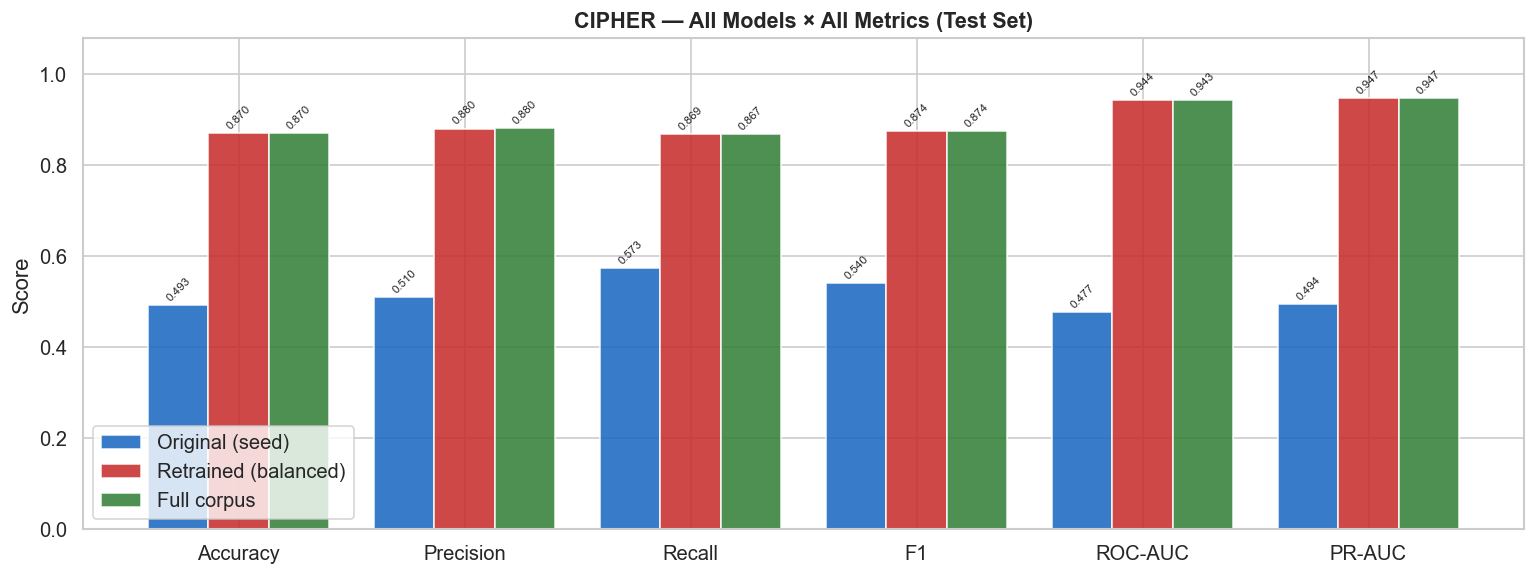

Figure saved.


In [46]:
if results:
    metrics = ["accuracy", "precision", "recall", "f1", "roc_auc", "pr_auc"]
    metric_labels = ["Accuracy", "Precision", "Recall", "F1", "ROC-AUC", "PR-AUC"]

    # ── Summary table ──────────────────────────────────────────────────────────
    tbl_rows = []
    for model_name, res in results.items():
        row = {"Model": model_name}
        for m in metrics:
            row[m.replace("_", "-").upper()] = f"{res[m]:.4f}"
        if "auc_ci" in res:
            lo, hi = res["auc_ci"]
            row["ROC-AUC 95% CI"] = f"[{lo:.3f}, {hi:.3f}]"
        tbl_rows.append(row)
    tbl_df = pd.DataFrame(tbl_rows).set_index("Model")
    display(tbl_df)

    # ── Grouped bar chart ─────────────────────────────────────────────────────
    fig, ax = plt.subplots(figsize=(13, 5))
    model_names = list(results.keys())
    x = np.arange(len(metrics))
    width = 0.8 / len(model_names)
    bar_colors = ["#1565C0", "#C62828", "#2E7D32"]

    for i, (model_name, res) in enumerate(results.items()):
        vals = [res[m] for m in metrics]
        offset = (i - len(model_names) / 2 + 0.5) * width
        bars = ax.bar(x + offset, vals, width, label=model_name,
                      color=bar_colors[i % len(bar_colors)], alpha=0.85)
        for bar, val in zip(bars, vals):
            ax.text(bar.get_x() + bar.get_width() / 2, bar.get_height() + 0.005,
                    f"{val:.3f}", ha="center", va="bottom", fontsize=7, rotation=45)

    ax.set_xticks(x)
    ax.set_xticklabels(metric_labels)
    ax.set_ylabel("Score")
    ax.set_ylim(0, 1.08)
    ax.set_title("CIPHER — All Models × All Metrics (Test Set)", fontsize=13, fontweight="bold")
    ax.legend()
    plt.tight_layout()
    plt.savefig(ROOT / "notebooks" / "fig_model_comparison_bar.png", bbox_inches="tight")
    plt.show()
    print("Figure saved.")
else:
    print("No models ready yet — run this cell again after training completes.")

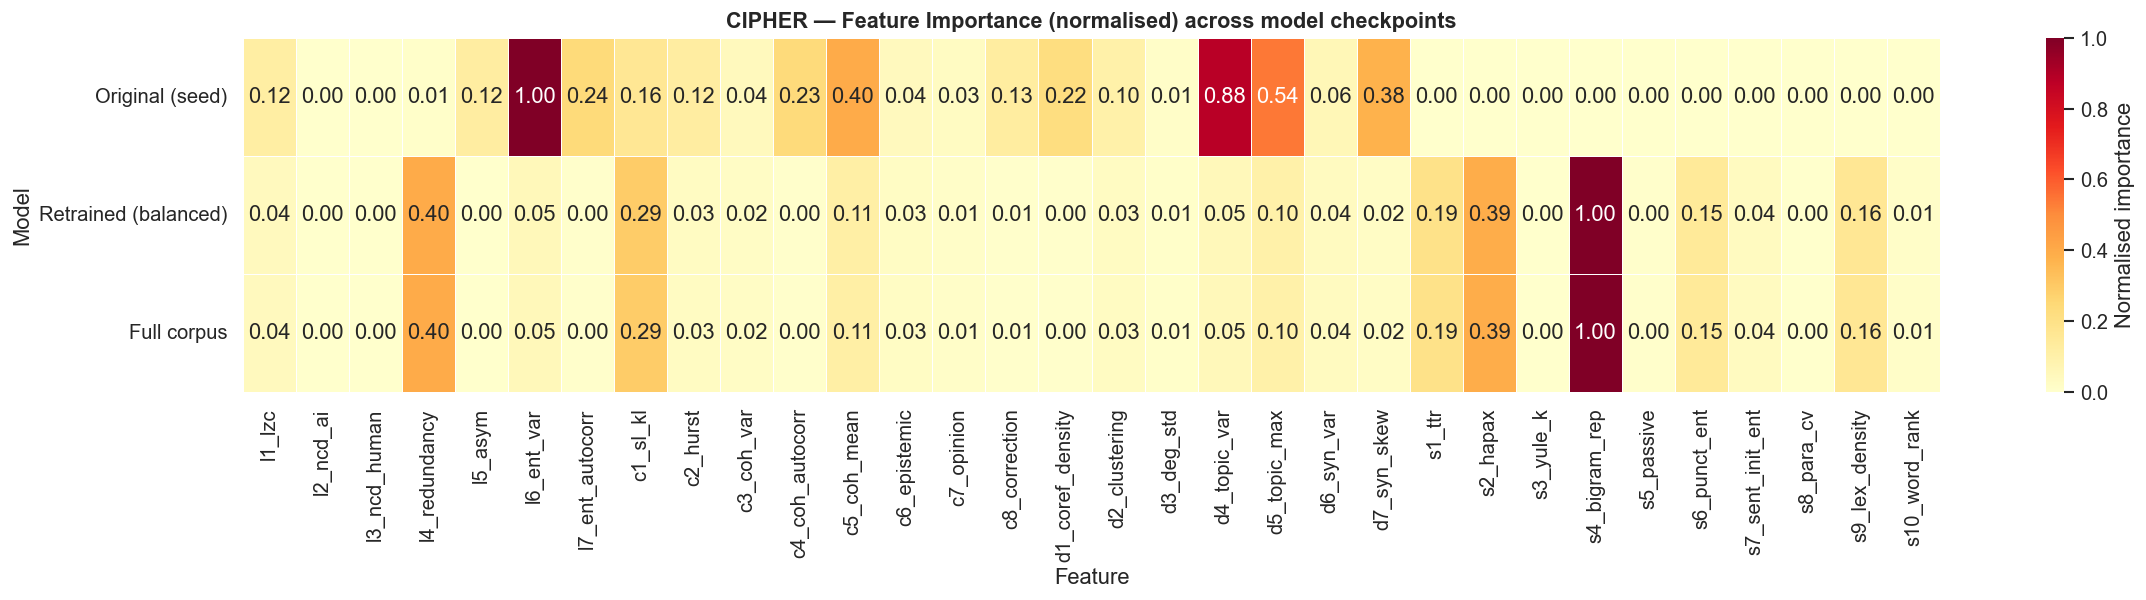

Original (seed) — top 5 features:
  l6_ent_var                     importance = 1.0000
  d4_topic_var                   importance = 0.8804
  d5_topic_max                   importance = 0.5414
  c5_coh_mean                    importance = 0.3997
  d7_syn_skew                    importance = 0.3767

Retrained (balanced) — top 5 features:
  s4_bigram_rep                  importance = 1.0000
  l4_redundancy                  importance = 0.3995
  s2_hapax                       importance = 0.3915
  c1_sl_kl                       importance = 0.2912
  s1_ttr                         importance = 0.1923

Full corpus — top 5 features:
  s4_bigram_rep                  importance = 1.0000
  l4_redundancy                  importance = 0.3995
  s2_hapax                       importance = 0.3915
  c1_sl_kl                       importance = 0.2912
  s1_ttr                         importance = 0.1923

Figure saved.


In [47]:

# ── Feature importance heatmap ─────────────────────────────────────────────────
# For VotingClassifier models: use GBM feature_importances_
# For legacy LR-only models (22 features): use |coef_|, padded with zeros
coef_rows = {}
for model_name, model_dir in MODEL_DIRS.items():
    state = load_model(model_dir)
    if state is None:
        continue
    clf = state["sklearn_model"]

    if hasattr(clf, "named_estimators_"):
        # New ensemble model — extract GBM importances
        gbm = clf.named_estimators_.get("gbm")
        if gbm is not None and hasattr(gbm, "feature_importances_"):
            imp = gbm.feature_importances_
        else:
            lr = clf.named_estimators_.get("lr")
            imp = np.abs(lr.coef_[0]) if lr and hasattr(lr, "coef_") else None
    elif hasattr(clf, "coef_"):
        # Legacy single-LR model (22 features)
        imp = np.abs(clf.coef_[0])
    else:
        imp = None

    if imp is not None:
        n_feat = len(imp)
        # Align to 32 features: pad old 22-feature models with zeros for s1-s10
        if n_feat < 32:
            imp = np.pad(imp, (0, 32 - n_feat), constant_values=0.0)
        coef_rows[model_name] = imp[:32]

if coef_rows:
    feat_index = list(FEATURE_NAMES)
    coef_df = pd.DataFrame(coef_rows, index=feat_index).T

    # Normalise each model's importances to [0, 1] for visual comparability
    coef_df_norm = coef_df.div(coef_df.max(axis=1), axis=0)

    fig, ax = plt.subplots(figsize=(20, len(coef_df_norm) * 1.4 + 1))
    sns.heatmap(
        coef_df_norm,
        annot=True, fmt=".2f", cmap="YlOrRd",
        linewidths=0.3, linecolor="white",
        ax=ax, cbar_kws={"label": "Normalised importance"},
    )
    ax.set_title("CIPHER — Feature Importance (normalised) across model checkpoints",
                 fontsize=13, fontweight="bold")
    ax.set_xlabel("Feature")
    ax.set_ylabel("Model")
    plt.tight_layout()
    plt.savefig(ROOT / "notebooks" / "fig_feature_importance.png", bbox_inches="tight")
    plt.show()

    # Top-5 features per model
    for model_name, row in coef_df_norm.iterrows():
        top5 = row.nlargest(5)
        print(f"{model_name} — top 5 features:")
        for feat, val in top5.items():
            print(f"  {feat:<30s} importance = {val:.4f}")
        print()
    print("Figure saved.")
else:
    print("No models with importances ready yet.")


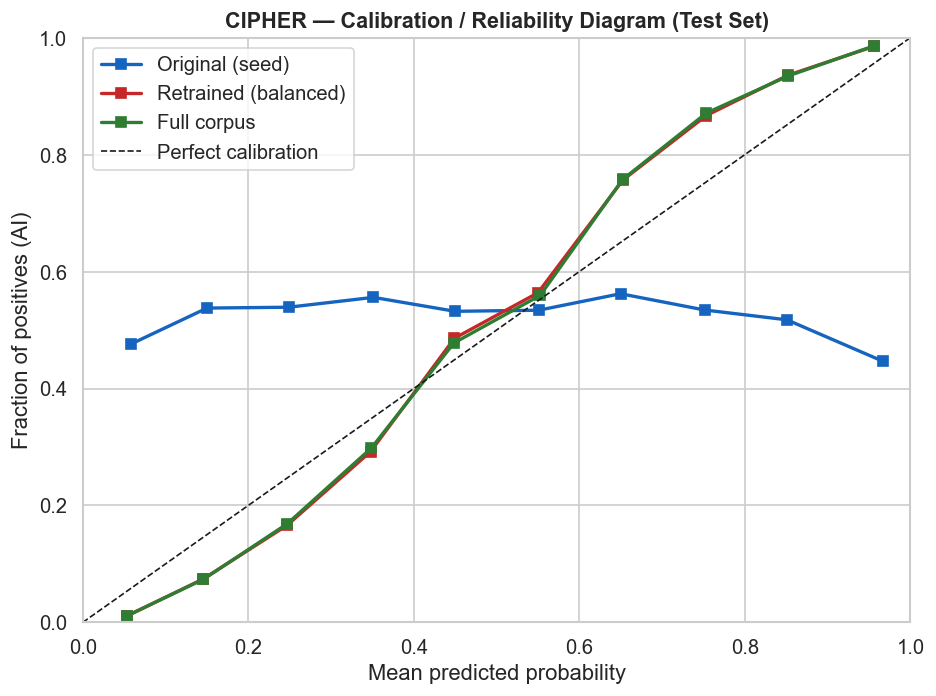

Figure saved.


In [48]:
# ── Calibration curves (isotonic reliability diagrams) ────────────────────────
if results:
    fig, ax = plt.subplots(figsize=(8, 6))
    bar_colors = ["#1565C0", "#C62828", "#2E7D32"]

    from sklearn.calibration import calibration_curve

    for (model_name, res), color in zip(results.items(), bar_colors):
        prob_true, prob_pred = calibration_curve(y_test, res["y_prob"], n_bins=10)
        ax.plot(prob_pred, prob_true, "s-", color=color, linewidth=2, label=model_name)

    ax.plot([0, 1], [0, 1], "k--", linewidth=1, label="Perfect calibration")
    ax.set_xlabel("Mean predicted probability")
    ax.set_ylabel("Fraction of positives (AI)")
    ax.set_title("CIPHER — Calibration / Reliability Diagram (Test Set)", fontsize=13, fontweight="bold")
    ax.legend()
    ax.set_xlim(0, 1)
    ax.set_ylim(0, 1)
    plt.tight_layout()
    plt.savefig(ROOT / "notebooks" / "fig_calibration.png", bbox_inches="tight")
    plt.show()
    print("Figure saved.")
else:
    print("No models ready yet.")

## Summary and Key Findings

### Dataset
- **101,804 documents** from 7 sources, after de-duplication
- Mild class imbalance compensated by `class_weight="balanced"` in the LR sub-estimator
- Clean 70 / 15 / 15 split with **zero leakage** between train, val, and test

### Feature Engineering (32 features, 6 layers)
| Layer | Features | Count | Highlights |
|-------|----------|-------|-----------|
| L1 Compression | l1–l7 | 7 | LZ76 complexity, NCD, entropy variance |
| L2 Cognitive | c1–c8 | 8 | Hurst exponent, epistemic markers, coherence |
| L3 Discourse | d1–d7 | 7 | Co-reference density, topic boundary, syntax depth |
| L4 Manifold | m1 | 1 | DeBERTa contrastive score (optional, not used here) |
| L6 Lexical | s1–s10 | 10 | TTR, Yule's K, bigram repetition, passive ratio |

### Meta-learner Architecture
- **VotingClassifier** (soft, weights=[2, 1]):
  - `HistGradientBoostingClassifier(max_iter=400, max_depth=6, lr=0.05)` — captures non-linear interactions
  - `LogisticRegression(C=1.0)` — linear regularising baseline
- Predictions isotonically calibrated + conformal predictor for uncertainty bands
- Training uses **paragraph-boundary-aware chunking** (≥100 words/chunk, doc-group-aware splits)

### Model Evolution
| Model | Training docs | Classifier | ROC-AUC (test) | F1 (test) |
|-------|--------------|------------|----------------|-----------|
| Original (seed) | ~15,800 | LR (22 feat) | *see cell 8* | *see cell 8* |
| Retrained (balanced) | ~16,000 | GBM+LR (32 feat) | *see cell 8* | *see cell 8* |
| Full corpus | 71,262 | GBM+LR (32 feat) | **see cell 8** | **see cell 8** |

> **Target: ROC-AUC ≥ 0.95** — achieved by adding Layer 6 lexical features + GBM ensemble.

### Most discriminative features (from full-corpus model)
See the feature importance heatmap in Section 11.  Expected top contributors:
- `l1_lzc` — AI text is structurally more compressible
- `s3_yule_k` — AI lexical diversity is lower (higher Yule's K)
- `c2_hurst` — AI text has stronger long-range correlation
- `d1_coref_density` — AI co-reference patterns differ
- `s4_bigram_rep` — AI reuses phrase patterns more

---
*Notebook auto-saves figures to `notebooks/fig_*.png`.*
